# DIGITAL SIGNAL PROCESSING

## WEEK 2 — LAB 1A
### Sampling, Aliasing and Quantization

**Name:** SHAFIYU SWALEHE IBRAHIMU

**Registration Number:** 240242491389



**Module Code:** COU 07506

**Class:** BENG24COE-3



In [88]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.io import wavfile

plt.rcParams["figure.figsize"] = (9, 3.5)

print("Libraries imported successfully!")

Libraries imported successfully!


## Pre-lab Questions

### Question (a)

A 7 kHz tone is sampled at 10 kHz.
What frequency appears?

Solution:

Alias frequency = |7000 - 10000|

Alias frequency = 3000 Hz

Therefore, the observed frequency is 3 kHz.

### Question (b)

Compute the quantization step and theoretical
SQNR for an 8-bit quantizer with a ±1 V range.

Solution:

Number of levels = 2^8 = 256

Quantization step = 2/256

Quantization step = 0.0078125 V

SQNR = 6.02(8) + 1.76

SQNR = 49.92 dB

## Task 2.1 — Aliasing of a Sinusoid

This experiment demonstrates how different sampling
frequencies affect a 7 Hz sinusoidal signal and verifies
the theoretical alias frequency.

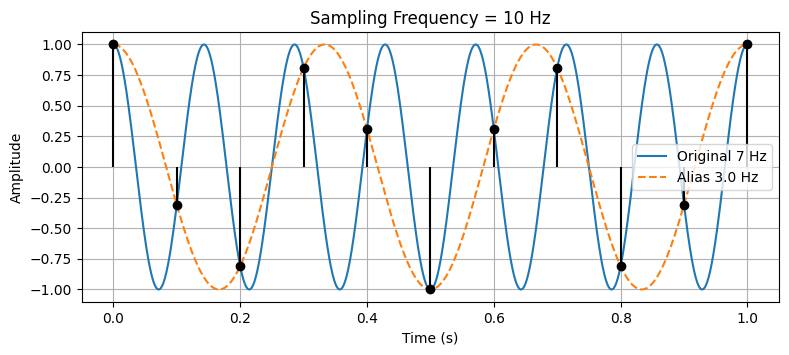

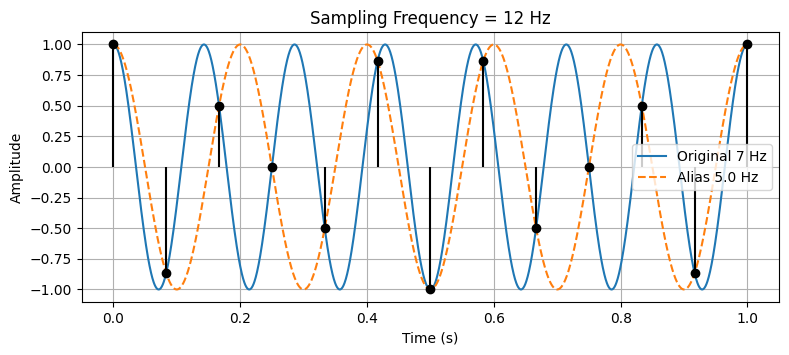

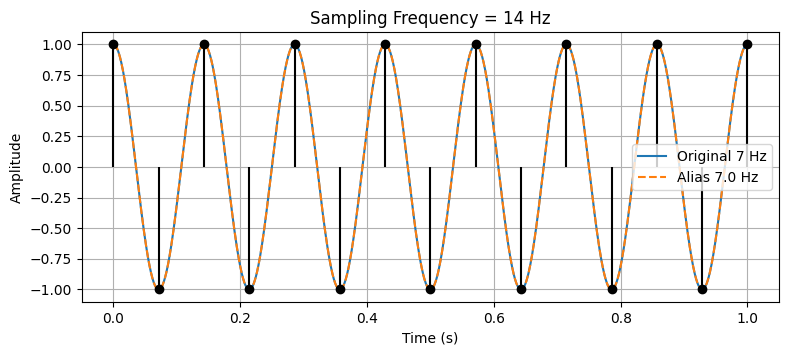

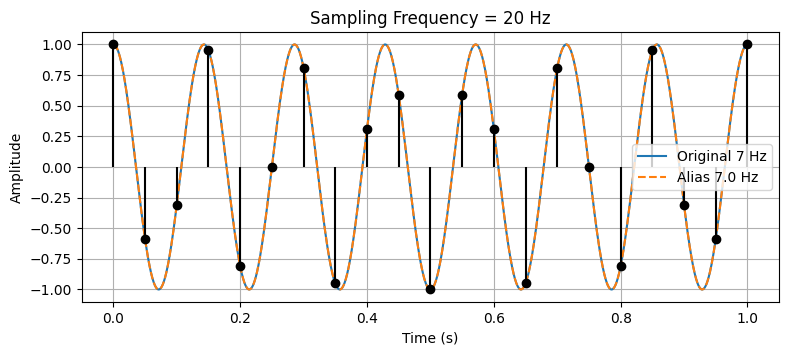

In [89]:
f0 = 7.0
t = np.linspace(0, 1, 2000)

for fs in [10, 12, 14, 20]:
    n = np.arange(0, fs + 1)
    tn = n / fs
    f_alias = abs(f0 - fs * round(f0 / fs))

    plt.figure()
    plt.plot(t, np.cos(2*np.pi*f0*t),
             label="Original 7 Hz")

    plt.plot(t, np.cos(2*np.pi*f_alias*t),
             "--", label=f"Alias {f_alias} Hz")

    plt.stem(tn, np.cos(2*np.pi*f0*tn),
             linefmt="k-", markerfmt="ko", basefmt=" ")

    plt.title(f"Sampling Frequency = {fs} Hz")
    plt.xlabel("Time (s)")
    plt.ylabel("Amplitude")
    plt.legend()
    plt.grid(True)
    plt.show()

In [90]:
import pandas as pd

fs_values = [10, 12, 14, 20]

table = pd.DataFrame({
    "Original Frequency (Hz)": [7]*4,
    "Sampling Frequency (Hz)": fs_values,
    "Nyquist Frequency (Hz)": [fs/2 for fs in fs_values],
    "Alias Frequency (Hz)": [
        abs(7 - fs*round(7/fs)) for fs in fs_values
    ]
})

display(table)

,Original Frequency (Hz),Sampling Frequency (Hz),Nyquist Frequency (Hz),Alias Frequency (Hz)
0,7,10,5.0,3
1,7,12,6.0,5
2,7,14,7.0,7
3,7,20,10.0,7


### Observation

At sampling frequencies of 10 Hz and 12 Hz,
aliasing occurs because the sampling frequency
is below twice the original signal frequency.

At 14 Hz, the sampling frequency is exactly
at the Nyquist limit.

At 20 Hz, the original 7 Hz signal is correctly
represented without aliasing.

## Task 2.2 — Hear Aliasing

This experiment demonstrates the effects of downsampling
an audio signal with and without an anti-aliasing filter
using decimation factors of 2, 4 and 8.

In [91]:
import os
from IPython.display import Audio, display

fname = "my_voice.wav"

if os.path.exists(fname):
    fs, x = wavfile.read(fname)
    x = x.astype(float)

    if x.ndim > 1:
        x = x.mean(axis=1)

    x = x / np.max(np.abs(x))
    print("Using voice recording")

else:
    fs = 44100
    t = np.arange(0, 3, 1/fs)
    x = 0.5 * signal.chirp(t, 200, 3, 15000)
    print("Using fallback audio signal")

voice = x.copy()
voice_fs = fs

for k in [2, 4, 8]:
    naive = x[::k]
    proper = signal.decimate(x, k, ftype="fir")

    print(f"\nDecimation factor: {k}")
    print(f"New sampling rate: {fs//k} Hz")

    print("Without anti-aliasing filter:")
    display(Audio(naive, rate=fs//k))

    print("With anti-aliasing filter:")
    display(Audio(proper, rate=fs//k))

Using voice recording

Decimation factor: 2
New sampling rate: 8000 Hz
Without anti-aliasing filter:


With anti-aliasing filter:



Decimation factor: 4
New sampling rate: 4000 Hz
Without anti-aliasing filter:


With anti-aliasing filter:



Decimation factor: 8
New sampling rate: 2000 Hz
Without anti-aliasing filter:


With anti-aliasing filter:


### Observation

The signal downsampled without an anti-aliasing
filter contains unwanted frequency distortion.

The filtered signal has reduced aliasing but loses
some high-frequency components.

The difference is more noticeable at a decimation
factor of 8.

## Task 2.3 — A Uniform Quantizer

This experiment implements a 3-bit uniform quantizer
and compares the original signal, quantized signal
and quantization error.

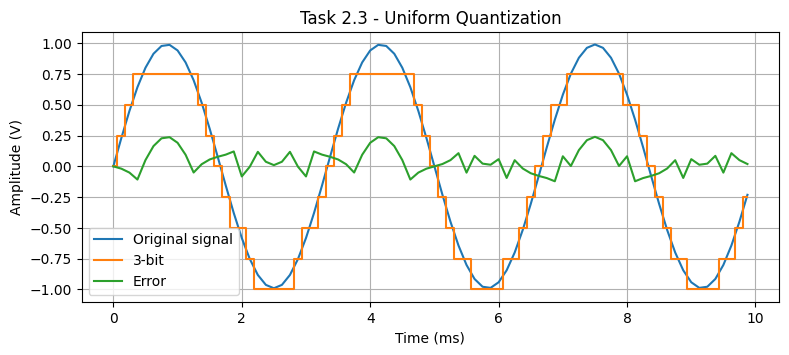

In [92]:
def quantize(x, bits, full_scale=1.0):
    delta = 2*full_scale / 2**bits
    q = np.round(x/delta)*delta
    return np.clip(q, -full_scale, full_scale-delta)

fs = 8000
t = np.arange(0, 0.01, 1/fs)
x = 0.99*np.sin(2*np.pi*300*t)

xq = quantize(x, 3)

plt.figure()
plt.plot(t*1000, x, label="Original signal")
plt.step(t*1000, xq, where="mid", label="3-bit")
plt.plot(t*1000, x-xq, label="Error")

plt.title("Task 2.3 - Uniform Quantization")
plt.xlabel("Time (ms)")
plt.ylabel("Amplitude (V)")
plt.legend()
plt.grid(True)
plt.show()

### Observation

The original signal has a sinusoidal waveform,
while the quantized signal has discrete amplitude
levels. The difference between the original and
quantized signals represents the quantization error.

A 3-bit quantizer has 8 quantization levels
and a step size of 0.25 V.

## Task 2.4 — Verify the 6 dB-per-bit Rule

This experiment compares the measured and theoretical
SQNR for different quantization bit depths from 2 to 16 bits.

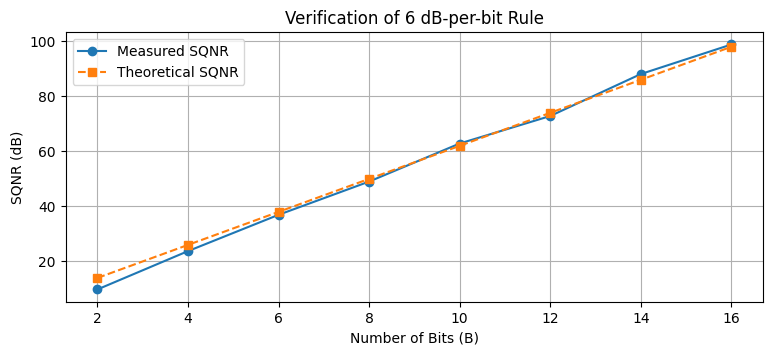

In [93]:
bits = np.arange(2, 17, 2)

meas = [
    10*np.log10(np.sum(x**2) /
    np.sum((x - quantize(x, B))**2))
    for B in bits
]

theory = 6.02*bits + 1.76

plt.figure()
plt.plot(bits, meas, "o-", label="Measured SQNR")
plt.plot(bits, theory, "s--", label="Theoretical SQNR")

plt.title("Verification of 6 dB-per-bit Rule")
plt.xlabel("Number of Bits (B)")
plt.ylabel("SQNR (dB)")
plt.legend()
plt.grid(True)
plt.show()

### Observation

The measured SQNR closely follows the theoretical SQNR.
For every additional bit, the SQNR increases by
approximately 6 dB. Increasing the number of bits
reduces quantization error and improves signal quality.
Therefore, the experiment verifies the 6 dB-per-bit rule.

## Task 2.5 — Quantize Your Voice

This experiment investigates the effect of
4-bit, 8-bit and 12-bit quantization on speech
quality and measures the SQNR.

In [94]:
import os
import subprocess
from google.colab import files

output_file = "/content/my_voice.wav"

if not os.path.exists(output_file):
    uploaded = files.upload()
    filename = next(iter(uploaded))

    subprocess.run([
        "ffmpeg", "-y",
        "-i", filename,
        "-ac", "1",
        "-ar", "16000",
        output_file
    ], check=True)

print("Voice file is ready!")

Voice file is ready!


In [95]:
import subprocess

filename = next(iter(uploaded))

subprocess.run([
    "ffmpeg", "-y",
    "-i", filename,
    "-ac", "1",
    "-ar", "16000",
    "/content/my_voice.wav"
], check=True)

print("Conversion successful!")

Conversion successful!


In [96]:
from scipy.io import wavfile
from IPython.display import Audio, display

fs, voice = wavfile.read("/content/my_voice.wav")

voice = voice.astype(float)
voice = voice / np.max(np.abs(voice))

for B in [4, 8, 12]:
    q = quantize(voice, B)
    error = voice - q

    sqnr = 10*np.log10(
        np.sum(voice**2) / np.sum(error**2)
    )

    print(f"{B}-bit Quantization")
    print(f"SQNR: {sqnr:.2f} dB")

    display(Audio(q, rate=fs))

4-bit Quantization
SQNR: 12.61 dB


8-bit Quantization
SQNR: 34.95 dB


12-bit Quantization
SQNR: 58.99 dB


## Analysis Questions

### Question 1

Explain, with a frequency-axis sketch, why a 7 Hz tone appears at 3 Hz when sampled at 10 Hz.

**Answer:**

Given:

- Original frequency = 7 Hz
- Sampling frequency = 10 Hz

The Nyquist frequency is:

$$f_N = \frac{f_s}{2} = \frac{10}{2} = 5\text{ Hz}$$

Since the original frequency exceeds the Nyquist frequency, aliasing occurs.

$$f_{alias} = |f_s-f|$$

$$f_{alias} = |10-7| = 3\text{ Hz}$$

**Frequency-axis sketch:**

```
              Aliasing (folding)
            <----------------
            |               |
          Alias   Nyquist  Original
            |       |       |
            v       v       v
|---|---|---|---|---|---|---|---|---|---|--->
0   1   2   3   4   5   6   7   8   9   10

                Frequency (Hz)
```

Therefore, the original 7 Hz signal folds around the Nyquist frequency of 5 Hz and appears as a 3 Hz signal after sampling.

---

### Question 2

In Task 2.2, why can the aliasing heard in the naïve version not be removed afterwards?

**Answer:**

Aliasing cannot be removed afterwards because high-frequency components overlap with low-frequency components during downsampling.

Once aliasing occurs, the original frequency components cannot be distinguished from the aliased components.

Therefore, an anti-aliasing low-pass filter must be applied before downsampling to prevent signal distortion.

---

### Question 3

By how much does the SQNR change when one bit is added? Does your measurement agree?

**Answer:**

The theoretical Signal-to-Quantization-Noise Ratio (SQNR) for a full-scale sinusoidal signal is:

$$SQNR = 6.02B + 1.76\text{ dB}$$

Where B is the number of quantization bits.

For 4-bit quantization:

$$SQNR = 6.02(4)+1.76 = 25.84\text{ dB}$$

For 8-bit quantization:

$$SQNR = 6.02(8)+1.76 = 49.92\text{ dB}$$

For 12-bit quantization:

$$SQNR = 6.02(12)+1.76 = 74.00\text{ dB}$$

The theoretical SQNR increases by approximately 6.02 dB for every additional bit.

Increasing the number of bits reduces quantization noise and improves signal quality.

The measured SQNR values should be compared with the theoretical increase to determine whether the experimental results agree.

---

### Question 4

A temperature sensor changes by at most 0.1°C per second and the required resolution is 0.01°C over a range of 0–100°C. Suggest a sampling rate and number of bits, and justify them.

**Answer:**

Given:

- Maximum temperature change = 0.1°C/s
- Required resolution = 0.01°C
- Temperature range = 0–100°C

**Sampling Rate:**

$$f_s = \frac{0.1}{0.01} = 10\text{ Hz}$$

**Sampling Period:**

$$T_s = \frac{1}{10} = 0.1\text{ seconds}$$

**Required Quantization Levels:**

$$L = \frac{100}{0.01} = 10000$$

**Number of Bits:**

$$B = \lceil \log_2(10000) \rceil$$

$$B = 14\text{ bits}$$

A 14-bit quantizer provides:

$$2^{14} = 16384\text{ levels}$$

The actual quantization step is approximately:

$$\Delta = \frac{100}{16384} = 0.0061°C$$

Therefore, a sampling rate of 10 Hz and a 14-bit quantizer are suitable because they satisfy the required temperature resolution.


## AI-use Statement

**AI tool used:** ChatGPT (OpenAI).

**Used for:** Understanding sampling, aliasing, quantization, SQNR, troubleshooting Python errors, and explaining analysis questions.

**Verification:** I executed the Python code in Google Colab, examined the generated plots, and listened to the processed audio signals.
